In [1]:
#import corner
import numpy as np
import random
import pandas as pd
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib import dates
from sklearn.metrics import mean_squared_error, r2_score
from datetime import datetime
from lmfit import Minimizer, Parameters, Parameter, report_fit, printfuncs, conf_interval,minimize
from statsmodels.tsa.arima_model import ARIMA

In [3]:
csv_url="https://raw.githubusercontent.com/ADelau/proj0016-epidemic-data/main/groupe10.csv"
data = pd.read_csv(csv_url)
data['day_hospitalization']=data['num_cumulative_hospitalizations'].diff().shift(periods=-1)

In [4]:
data

,Day,num_positive,num_tested,num_hospitalised,num_cumulative_hospitalizations,num_critical,num_fatalities,day_hospitalization
0,1,0,0,1,1,0,0,0.0
1,2,5,8,1,1,0,0,1.0
2,3,10,12,2,2,0,0,0.0
3,4,11,16,2,2,0,0,0.0
4,5,9,12,2,2,0,0,0.0
...,...,...,...,...,...,...,...,...
186,187,0,0,0,4671,0,537,0.0
187,188,0,0,0,4671,0,537,0.0
188,189,0,0,0,4671,0,537,0.0
189,190,0,0,0,4671,0,537,0.0


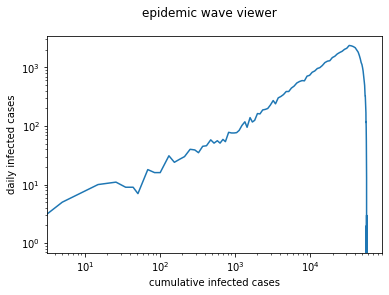

In [11]:
fig = plt.figure()

plt.loglog(data['num_positive'].cumsum(),data['num_positive'])
fig.suptitle('epidemic wave viewer')
plt.xlabel('cumulative infected cases')
plt.ylabel('daily infected cases')

plt.savefig('loglog.png')